In [47]:
# lo so è pieno di roba inutile

import numpy as np
import pandas as pd
from itertools import cycle
from matplotlib.path import Path as MplPath
import tifffile
import sys
from pathlib import Path
import plotly.graph_objects as go
from phasorpy.plot import PhasorPlot     # phasor plot stolen from phasorpy 

# personal stuff
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
from iminuit import Minuit, cost

import lib.randgen
import lib.my_stats

# 1. Exponential data generation

In [48]:
τ_true = 3 # ns
N_evt = 10000

tempi = np.random.exponential(scale = τ_true, size = N_evt)
n, xe = np.histogram(tempi, bins='auto')   
    # xe = bin edges, n = bin heights


<h3> Binned NNL fit (only made for comparison purposes)

In [49]:
def expon_cdf(x, A, τ):
    return A * τ * (1.0 - np.exp(-x / τ))   # I need cdf for the binned likelihood 


#fixing crazy chi squared results
A_guess, tau_guess = n[0], np.mean(tempi)

c_binned = cost.ExtendedBinnedNLL(n, xe, expon_cdf)
m = Minuit(c_binned, A = A_guess, τ = tau_guess)
m.limits["τ"], m.limits["A"] = (0.001, None), (0.001, None)     # placing lower limits on both parameters to avoid negative values
m.migrad()

print("Params")
# if i dont leave an empty line, params will not display for some reason
display(m.params)

print("\nStats")
lib.my_stats.minuit_stats(m)


Params


,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,A,3.33e3,0.05e3,,,0.001,,
1,τ,3.006,0.030,,,0.001,,



Stats
chi-squared: 57.00
reduced chi-squared: 0.79
dof: 72.00
p-value: 0.90


# 2. Phasor plot and noise addition

Functions for calculating and plotting phasors (given a histogram)

In [50]:
def phasor_calc (n, harm_n = 1):   # given a histogram n (xe), calculates the phasor coordinates G and S

    if add_noise_bool:
        n = add_noise(n, snr_db = 10) 

    fft_vals = np.fft.fft(n)
    fft_norm = fft_vals / fft_vals[0]
    
    G, S = np.real(fft_norm[harm_n]), -np.imag(fft_norm[harm_n])

    return G, S


#######################################################################################################



def data_and_phasor_plot(xe, n, G, S, T_laser):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (14, 5))

    # hist + plot
    bin_centers = 0.5 * (xe[:-1] + xe[1:])    # select bin centers

    ax1.hist(tempi, bins = xe, density = False, alpha = 0.3, color = 'steelblue', edgecolor = 'midnightblue', label = 'Data')
    
    ax1.plot(bin_centers, n, color = 'crimson', marker = '', linestyle = '-', linewidth = 1.5)

    ax1.set_xlabel('t (ns)', fontsize = 12)
    ax1.set_ylabel('counts', fontsize = 12)
    #ax1.legend(fontsize = 11, frameon = True, shadow = True)
    ax1.grid(alpha = 0.3)
    ax1.set_xlim(0, xe[-1])

    # phasor plane
    ω_laser = 1000.0 / T_laser  # Calcolo della frequenza in MHz
    plot = PhasorPlot(frequency = ω_laser, ax = ax2)

    plot.plot([G], [S], marker = 'x', markersize = 10, markeredgewidth = 2, 
              color = 'crimson', label = 'Fasore (Dati)')

    #ax2.legend(loc='upper right', fontsize=11, frameon=True, shadow=True)

    plt.tight_layout()
    plt.show()



###################################################################################################



def add_noise(counts, snr_db):   # snr_db = signal to noise ratio in dB         (controllare come funziona)

    rng = np.random.default_rng()   
    snr_linear = 10 ** (snr_db / 10)  # convert SNR from dB to linear scale 

    sig_power = np.mean(counts ** 2, axis = 0) 
    noise_std = np.sqrt(sig_power / snr_linear)
    noise = rng.standard_normal(counts.shape) * noise_std
    
    return np.clip(counts + noise, 0, None)


Testing phasor, plotting, and noise functions

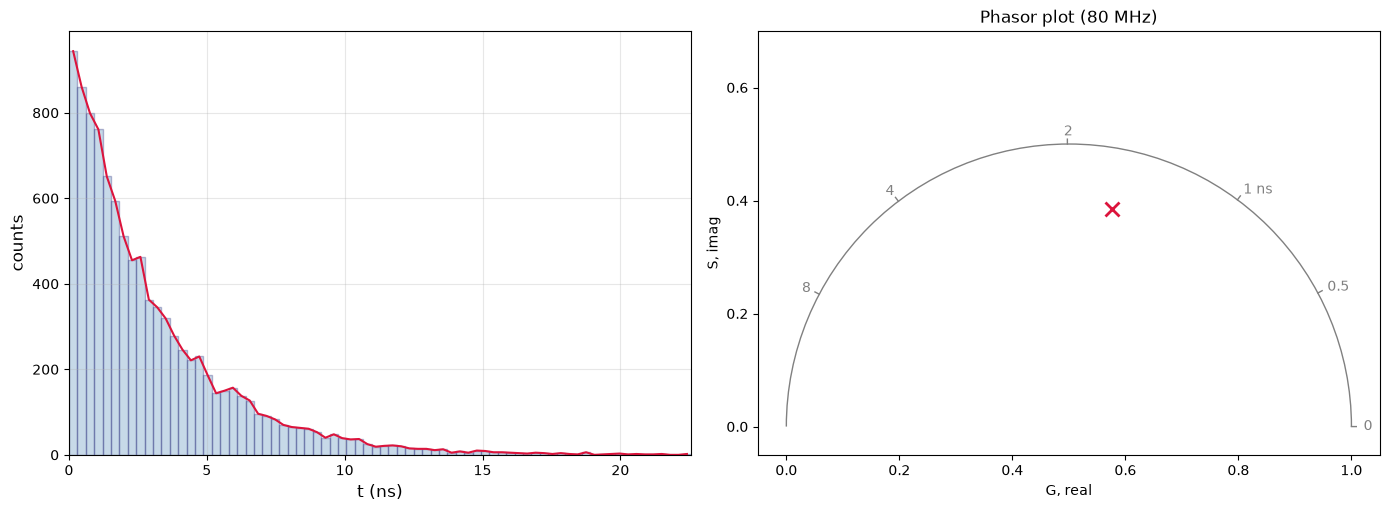

In [51]:

add_noise_bool = True  # set to True to add noise, False to keep original data

#phasors = [phasor_calc(n, harm_n) for harm_n in range(1, 4)]  # calculate phasors for the first three harmonics
#data_and_phasor_plot(xe, n, phasors[0][0], phasors[0][1], T_laser=12.5)  # [0][1] = first harmonic, S

phasors = phasor_calc(n, 1)   # commented the version that displays multiple harmonics
data_and_phasor_plot(xe, n, phasors[0], phasors[1], T_laser=12.5)


# 3. IRF Deconvolution

2 parole su cosa devo fare per vedere se ho capito. Spegazione presa dal file mmc5.pdf

IRF = Instrument Response Function, è la funzione di risposta al laser data dal rivelatore. È fondamentalmente il profilo temporale della risposta del sistema di rilevamento a un impulso laser brevissimo.

Il sistema di rilevamento infatti presenta sempre un errore nella risposta intrinseco dovuto a motivi fisici/elettronici (e quindi non riproducibile).
Studiare l'IRF permette di ottenere informazioni su questo errore e dunque correggere anche i dati di FLIM raccolti.

Nella pratica:
    decadimento rilevato = convoluzione(decadimento reale, IRF)

<h3> Cosa devo fare:

1. Generazione dati: genero una IRF artificiale (Gaussiana??), faccio convoluzione con [exp + rumore] (uso np.convolve visto che esiste)
2. Calcolo il fasore associato al segnale IRF (G_IRF, S_IRF)
3. Convoluzione in piano temporale = moltiplicazione nel piano dei fasori (rivedere appunti MxF)
        dunque: Z_calibrato = Z_grezzo / Z_IRF          
                (Z = G -iS)


NB: Il file specifica che nel dominio temporale dovrei fare una deconvoluzione iterativa (pesante) -> si può fare come confronto?